# EN3160 Assignment 3: Neural Networks
**Name:** KPCP Keerawella  
**Index number:** 230332B  
**GitHub profile:** https://github.com/chalee88

This notebook evaluates a manually differentiated dense network on CIFAR-10, compares two MNIST classifiers, and compares full fine tuning with frozen feature extraction for ants and bees. All results use the complete dataset splits. Fixed image preprocessing is cached on the GPU when available; transfer-learning training augmentation remains fresh each epoch.


In [1]:
import os, random, time, copy, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms, models
from torchvision.datasets.utils import download_and_extract_archive
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
os.environ['TORCH_HOME'] = str(DATA / 'torch')
SEED = 42
def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
seed_all()
torch.set_num_threads(4)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cuda': print(torch.cuda.get_device_name(0))
def loader(ds, batch=128, shuffle=False):
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, num_workers=0,
                      pin_memory=device.type == 'cuda' and not (isinstance(ds, TensorDataset) and ds.tensors[0].is_cuda),
                      generator=torch.Generator().manual_seed(SEED))

def cache_fixed(ds):
    # Cache identical fixed views once, preserving every image and label.
    if device.type != 'cuda': return ds
    batches = list(DataLoader(ds, batch_size=512, shuffle=False, num_workers=0))
    x = torch.cat([b[0] for b in batches]).to(device)
    y = torch.cat([b[1] for b in batches]).to(device)
    return TensorDataset(x, y)

def curves(history, title, eval_label='test'):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        for split in ['train', 'test']:
            ax.plot(h.epoch, h[f'{split}_{metric}'], marker='o', label=split if split == 'train' else eval_label)
        ax.set(xlabel='Epoch', ylabel=metric.title(), title=title + ': ' + metric)
        ax.legend(); ax.grid(alpha=.25)
    fig.tight_layout(); plt.show()

def confusion(matrix, labels, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(matrix, cmap='Blues')
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(matrix[i,j]), ha='center', va='center',
                    color='white' if matrix[i,j] > matrix.max()/2 else 'black', fontsize=8)
    ax.set(xticks=range(len(labels)), yticks=range(len(labels)),
           xticklabels=labels, yticklabels=labels, xlabel='Predicted label',
           ylabel='True label', title=title)
    fig.colorbar(im, ax=ax); fig.tight_layout(); plt.show()

PyTorch: 2.5.1+cu121 | device: cuda
NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Manual forward and backward propagation on CIFAR-10
The network is $3072\to100\to10$, with sigmoid hidden units and linear logits. For a batch of size $N$,
$$H=\sigma(XW_1+b_1),\quad Z=HW_2+b_2,\quad L=-\frac1N\sum_i\log\operatorname{softmax}(Z_i)_{y_i}.$$
Using one-hot targets $Y$, the gradients are
$$G=(\operatorname{softmax}(Z)-Y)/N,\quad \nabla W_2=H^TG,\quad \nabla b_2=\sum_iG_i,$$
$$D=(GW_2^T)\odot H\odot(1-H),\quad \nabla W_1=X^TD,\quad \nabla b_1=\sum_iD_i.$$
All gradients use the old weights before any update. Log-sum-exp gives numerically stable cross-entropy. Training uses manual SGD, batch size 50, initial learning rate 0.1 and epoch decay 0.9 for 10 epochs, without regularization. The starter's tiny initialization and learning rate were designed for its different loss; Xavier initialization and the stated learning rate are used here to allow learning with averaged cross-entropy gradients.

100%|██████████| 170M/170M [1:09:10<00:00, 41.1kB/s] 


Extracting c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\cifar-10-python.tar.gz to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data
Files already downloaded and verified
Gradient check maximum absolute errors: [2.7755575615628914e-17, 6.938893903907228e-18, 4.163336342344337e-17, 8.326672684688674e-17]
{'epoch': 1, 'train_loss': 1.6900974397277833, 'train_accuracy': 0.41536, 'test_loss': 1.7069540559768677, 'test_accuracy': 0.4102}
{'epoch': 2, 'train_loss': 1.619198286895752, 'train_accuracy': 0.4444, 'test_loss': 1.6566701969146729, 'test_accuracy': 0.424}
{'epoch': 3, 'train_loss': 1.5584855765533447, 'train_accuracy': 0.46642, 'test_loss': 1.6127866903305055, 'test_accuracy': 0.442}
{'epoch': 4, 'train_loss': 1.5352719129180907, 'train_accuracy': 0.46862, 'test_loss': 1.6025387685775756, 'test_accuracy': 0.4404}
{'epoch': 5, 'train_loss': 1.4885477402496339, 'train_accuracy': 0.4897, 'test_loss': 1.5750037281036378, 'test_accuracy': 0.4513}
{'epoch': 6, '

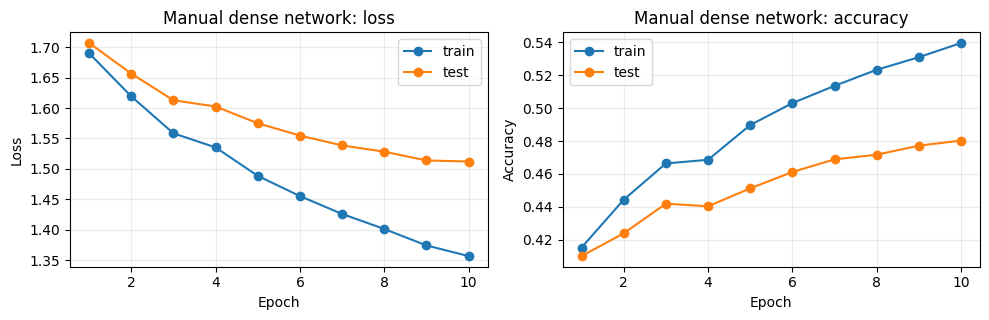

,epoch,train_loss,train_accuracy,test_loss,test_accuracy
9,10,1.356723,0.5395,1.512112,0.4803


In [2]:
cifar_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((.5,)*3, (.5,)*3)])
cifar_train = datasets.CIFAR10(DATA, train=True, download=True, transform=cifar_transform)
cifar_test = datasets.CIFAR10(DATA, train=False, download=True, transform=cifar_transform)
cifar_train, cifar_test = cache_fixed(cifar_train), cache_fixed(cifar_test)
cifar_loaders = {'train': loader(cifar_train, 50, True), 'test': loader(cifar_test, 256)}
seed_all()
W1 = torch.randn(3072, 100, device=device) * np.sqrt(2/(3072+100))
b1 = torch.zeros(100, device=device)
W2 = torch.randn(100, 10, device=device) * np.sqrt(2/110)
b2 = torch.zeros(10, device=device)

def manual_forward(x, params):
    w1, bias1, w2, bias2 = params
    h = torch.sigmoid(x @ w1 + bias1)
    return h, h @ w2 + bias2

def manual_gradients(x, y, params):
    h, z = manual_forward(x, params)
    loss = (torch.logsumexp(z, dim=1) - z[torch.arange(len(y), device=y.device), y]).mean()
    g = z.softmax(dim=1)
    g[torch.arange(len(y), device=y.device), y] -= 1
    g /= len(y)
    d = (g @ params[2].T) * h * (1-h)
    return loss, [x.T @ d, d.sum(0), h.T @ g, g.sum(0)]

# Autograd is used only to verify derivatives, never to train this model.
check_params = [p.detach().double().clone().requires_grad_() for p in [W1,b1,W2,b2]]
xcheck = torch.randn(4, 3072, device=device, dtype=torch.float64)
ycheck = torch.tensor([0,3,5,9], device=device)
_, zcheck = manual_forward(xcheck, check_params)
reference = torch.autograd.grad(nn.functional.cross_entropy(zcheck, ycheck), check_params)
with torch.no_grad():
    _, analytical = manual_gradients(xcheck, ycheck, check_params)
    errors = [float((a-b).abs().max()) for a,b in zip(reference, analytical)]
assert max(errors) < 1e-10
print('Gradient check maximum absolute errors:', errors)

@torch.no_grad()
def manual_evaluate(dl):
    total_loss = correct = count = 0
    for x,y in dl:
        x,y = x.to(device).flatten(1), y.to(device)
        _,z = manual_forward(x, [W1,b1,W2,b2])
        total_loss += nn.functional.cross_entropy(z,y,reduction='sum').item()
        correct += (z.argmax(1)==y).sum().item(); count += len(y)
    return total_loss/count, correct/count

manual_history = []
with torch.no_grad():
    for epoch in range(1,11):
        lr = .1 * .9**(epoch-1)
        for x,y in cifar_loaders['train']:
            x,y = x.to(device).flatten(1),y.to(device)
            _, grads = manual_gradients(x,y,[W1,b1,W2,b2])
            for p,g in zip([W1,b1,W2,b2],grads): p.add_(g, alpha=-lr)
        tr = manual_evaluate(cifar_loaders['train'])
        te = manual_evaluate(cifar_loaders['test'])
        row = dict(epoch=epoch,train_loss=tr[0],train_accuracy=tr[1],test_loss=te[0],test_accuracy=te[1])
        manual_history.append(row); print(row, flush=True)
pd.DataFrame(manual_history).to_csv(OUT/'manual_cifar10.csv', index=False)
curves(manual_history, 'Manual dense network')
display(pd.DataFrame(manual_history).tail(1))

## 2. LeNet-5 and a modern CNN on MNIST
Both networks use the same official 60,000/10,000 split, normalization, 32×32 inputs, batch size 128, Adam (learning rate 0.001, no weight decay), seed and 10 epochs. There is no augmentation. Test results are monitored as requested, but are not used for tuning or selecting a checkpoint. Metrics are measured in evaluation mode after each epoch on the complete sets, so dropout and batch normalization do not distort the comparison.

LeNet-5 uses 6 and 16 feature maps with 5×5 kernels, average pooling, tanh activations and 120/84 hidden units. This is the common fully connected C3, softmax-classifier adaptation of the original network (rather than its sparse C3 connections and RBF output). The modern model has exactly three convolution layers (32/64/128 channels), each with batch normalization and ReLU, plus dropout and global average pooling.

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:11<00:00, 873kB/s] 


Extracting c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw\train-images-idx3-ubyte.gz to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 72.2kB/s]


Extracting c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw\train-labels-idx1-ubyte.gz to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:02<00:00, 637kB/s]


Extracting c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw\t10k-images-idx3-ubyte.gz to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<00:00, 4.71MB/s]


Extracting c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw\t10k-labels-idx1-ubyte.gz to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\MNIST\raw

lenet5 parameters: 61706
lenet5 {'epoch': 1, 'train_loss': 0.11115678486824036, 'train_accuracy': 0.9681833333333333, 'test_loss': 0.10619743360579013, 'test_accuracy': 0.9656}
lenet5 {'epoch': 2, 'train_loss': 0.06038278032342593, 'train_accuracy': 0.98185, 'test_loss': 0.06615689109042287, 'test_accuracy': 0.9792}
lenet5 {'epoch': 3, 'train_loss': 0.038628211787839734, 'train_accuracy': 0.9883, 'test_loss': 0.049431482191570106, 'test_accuracy': 0.9847}
lenet5 {'epoch': 4, 'train_loss': 0.03717156898379326, 'train_accuracy': 0.9888666666666667, 'test_loss': 0.05038879799023271, 'test_accuracy': 0.9849}
lenet5 {'epoch': 5, 'train_loss': 0.026246701967716217, 'train_accuracy': 0.9922666666666666, 'test_loss': 0.04403311923732981, 'test_accuracy': 0.9861}
lenet5 {'epoch': 6, 'train_loss': 0.0238969564912219

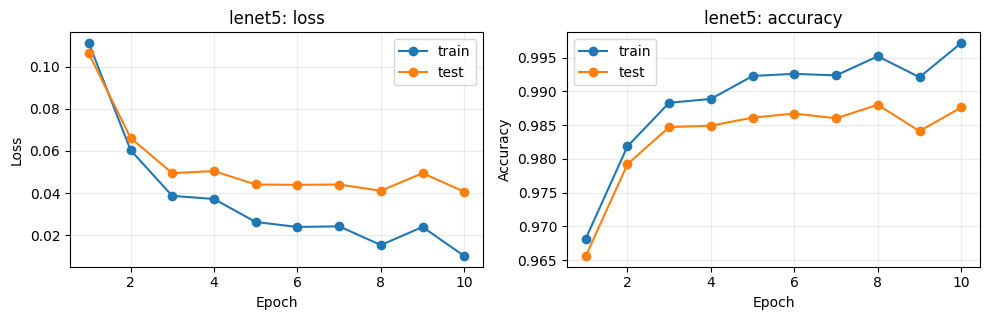

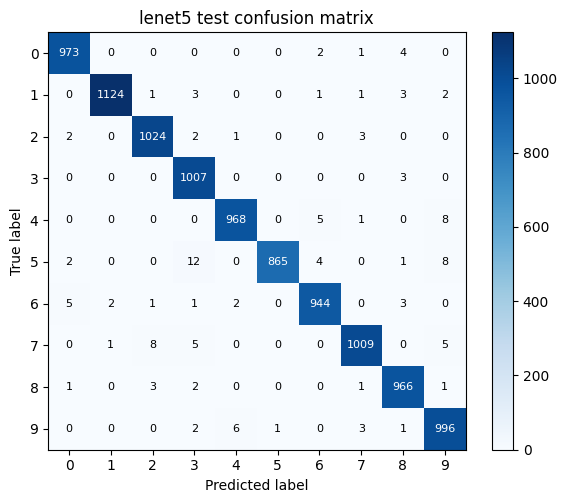

modern_cnn parameters: 94186
modern_cnn {'epoch': 1, 'train_loss': 0.2839802600860596, 'train_accuracy': 0.9525666666666667, 'test_loss': 0.2774457073926926, 'test_accuracy': 0.9562}
modern_cnn {'epoch': 2, 'train_loss': 0.11986080509026845, 'train_accuracy': 0.9720666666666666, 'test_loss': 0.11576335766911507, 'test_accuracy': 0.9745}
modern_cnn {'epoch': 3, 'train_loss': 0.09441060029268265, 'train_accuracy': 0.9754, 'test_loss': 0.09130837578773499, 'test_accuracy': 0.975}
modern_cnn {'epoch': 4, 'train_loss': 0.06672879984577497, 'train_accuracy': 0.9818333333333333, 'test_loss': 0.06505732904672623, 'test_accuracy': 0.9823}
modern_cnn {'epoch': 5, 'train_loss': 0.058786685331662494, 'train_accuracy': 0.9838833333333333, 'test_loss': 0.05835170459449291, 'test_accuracy': 0.9846}
modern_cnn {'epoch': 6, 'train_loss': 0.05050719499588013, 'train_accuracy': 0.9853666666666666, 'test_loss': 0.0537502236828208, 'test_accuracy': 0.9847}
modern_cnn {'epoch': 7, 'train_loss': 0.0483048059

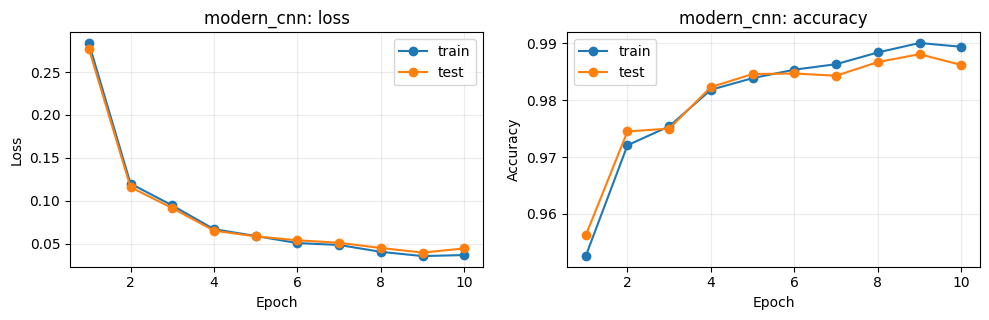

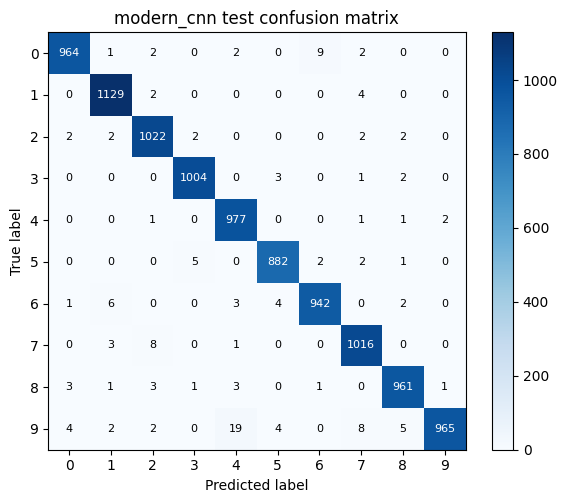

In [3]:
mnist_transform = transforms.Compose([transforms.Resize((32,32)), transforms.ToTensor(),
                                      transforms.Normalize((.1307,), (.3081,))])
mnist_train = datasets.MNIST(DATA, train=True, download=True, transform=mnist_transform)
mnist_test = datasets.MNIST(DATA, train=False, download=True, transform=mnist_transform)
mnist_train, mnist_test = cache_fixed(mnist_train), cache_fixed(mnist_test)

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1,6,5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6,16,5), nn.Tanh(), nn.AvgPool2d(2), nn.Flatten(),
            nn.Linear(16*5*5,120), nn.Tanh(), nn.Linear(120,84), nn.Tanh(), nn.Linear(84,10))
    def forward(self,x): return self.net(x)

class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1,bias=False), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1,bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(.2),
            nn.Conv2d(64,128,3,padding=1,bias=False), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(.5), nn.Linear(128,10))
    def forward(self,x): return self.net(x)

@torch.no_grad()
def evaluate(model, dl, classes):
    model.eval(); loss = correct = count = 0
    cm = torch.zeros(classes, classes, dtype=torch.int64)
    for x,y in dl:
        x,y = x.to(device),y.to(device)
        z = model(x); pred = z.argmax(1)
        loss += nn.functional.cross_entropy(z,y,reduction='sum').item()
        correct += (pred==y).sum().item(); count += len(y)
        cm += torch.bincount((y*classes+pred).cpu(), minlength=classes**2).reshape(classes,classes)
    return loss/count, correct/count, cm.numpy()

def train_model(model, train_dl, train_eval_dl, test_dl, epochs, optimizer, classes,
                frozen=False, scheduler=None, name='model'):
    history=[]; start=time.perf_counter()
    for epoch in range(1, epochs+1):
        model.train()
        # Frozen backbone must also keep its pretrained batch-normalization buffers fixed.
        if frozen:
            model.eval(); model.fc.train()
        for x,y in train_dl:
            x,y=x.to(device),y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss=nn.functional.cross_entropy(model(x),y)
            loss.backward(); optimizer.step()
        tr=evaluate(model,train_eval_dl,classes); te=evaluate(model,test_dl,classes)
        row=dict(epoch=epoch,train_loss=tr[0],train_accuracy=tr[1],test_loss=te[0],test_accuracy=te[1])
        history.append(row); print(name, row, flush=True)
        pd.DataFrame(history).to_csv(OUT/(name+'.csv'),index=False)
        if scheduler is not None: scheduler.step()
    elapsed=time.perf_counter()-start
    torch.save(model.state_dict(),OUT/(name+'.pt'))
    return history, te[2], elapsed

mnist_results={}
for name, constructor in [('lenet5',LeNet5),('modern_cnn',ModernCNN)]:
    seed_all()
    model=constructor().to(device)
    print(name, 'parameters:',sum(p.numel() for p in model.parameters()))
    result=train_model(model,loader(mnist_train,128,True),loader(mnist_train,256),
                       loader(mnist_test,256),10,torch.optim.Adam(model.parameters(),lr=.001),10,name=name)
    mnist_results[name]=result
    curves(result[0],name)
    confusion(result[1],list(range(10)),name+' test confusion matrix')
    assert result[1].sum()==len(mnist_test)

## 3. Transfer learning on ants and bees
Following the [official PyTorch tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial), load ResNet18 with ImageNet1K V1 weights and replace its classifier with two outputs. Fine tuning updates the entire network; feature extraction updates only the new classifier and keeps backbone parameters **and batch-normalization buffers** fixed. Each method starts from the same pretrained weights and identical seeded classifier initialization.

Both methods use 25 epochs, batch size 4, SGD with learning rate 0.001 and momentum 0.9, and a StepLR scheduler (factor 0.1 every 7 epochs). Training images use random resized crops and flips; evaluation uses deterministic resize and center crop, with ImageNet normalization. The supplied `val` split is a validation set, not an independent test set. Report final-epoch results rather than selecting the best validation epoch. Training accuracy is evaluated on deterministic training views and is directly comparable between methods.

100%|██████████| 47.3M/47.3M [00:26<00:00, 1.80MB/s]


Extracting c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\hymenoptera_data.zip to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data
Classes: ['ants', 'bees'] train: 244 validation: 153


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to c:\Users\Chaleesha\Documents\2026\Sem 5\CV\assignment 3\data\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:24<00:00, 1.93MB/s]


fine_tuning trainable parameters: 11177538
fine_tuning {'epoch': 1, 'train_loss': 0.14521786967506173, 'train_accuracy': 0.930327868852459, 'test_loss': 0.27273500121496863, 'test_accuracy': 0.8888888888888888}
fine_tuning {'epoch': 2, 'train_loss': 0.37372477742896765, 'train_accuracy': 0.819672131147541, 'test_loss': 0.6857649886530209, 'test_accuracy': 0.7516339869281046}
fine_tuning {'epoch': 3, 'train_loss': 0.0803705189285464, 'train_accuracy': 0.9754098360655737, 'test_loss': 0.2034086314291736, 'test_accuracy': 0.9215686274509803}
fine_tuning {'epoch': 4, 'train_loss': 0.08504310531205818, 'train_accuracy': 0.9672131147540983, 'test_loss': 0.27337079500061234, 'test_accuracy': 0.8954248366013072}
fine_tuning {'epoch': 5, 'train_loss': 0.0943237871053766, 'train_accuracy': 0.9713114754098361, 'test_loss': 0.24446535266302769, 'test_accuracy': 0.9084967320261438}
fine_tuning {'epoch': 6, 'train_loss': 0.022766074837475527, 'train_accuracy': 0.9918032786885246, 'test_loss': 0.3644

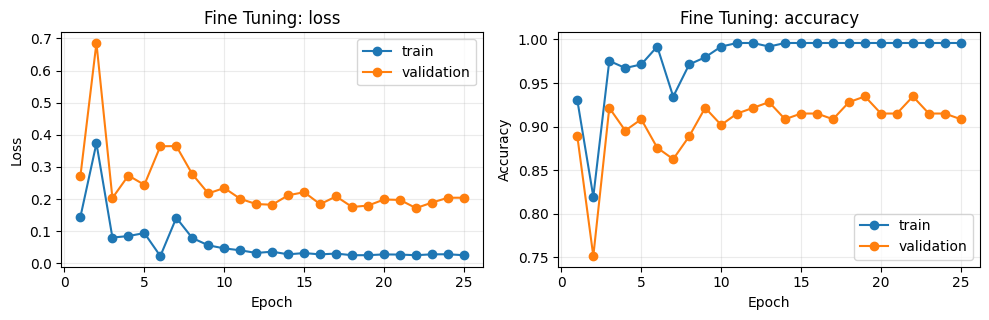

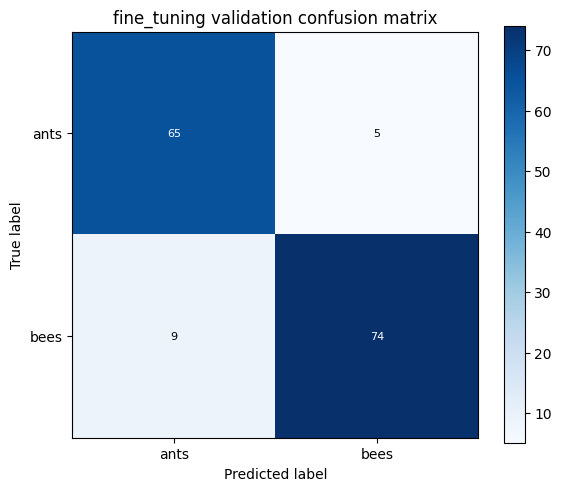

feature_extraction trainable parameters: 1026
feature_extraction {'epoch': 1, 'train_loss': 0.10026367680459726, 'train_accuracy': 0.9508196721311475, 'test_loss': 0.16283568097095863, 'test_accuracy': 0.934640522875817}
feature_extraction {'epoch': 2, 'train_loss': 0.08027559547822495, 'train_accuracy': 0.9754098360655737, 'test_loss': 0.12130567723629522, 'test_accuracy': 0.9607843137254902}
feature_extraction {'epoch': 3, 'train_loss': 0.05370035333955874, 'train_accuracy': 0.9836065573770492, 'test_loss': 0.12336205033694997, 'test_accuracy': 0.954248366013072}
feature_extraction {'epoch': 4, 'train_loss': 0.07666681091621762, 'train_accuracy': 0.9754098360655737, 'test_loss': 0.12459095192500969, 'test_accuracy': 0.9607843137254902}
feature_extraction {'epoch': 5, 'train_loss': 0.0425323365927964, 'train_accuracy': 0.9836065573770492, 'test_loss': 0.12168560659184176, 'test_accuracy': 0.9607843137254902}
feature_extraction {'epoch': 6, 'train_loss': 0.03537238239631301, 'train_acc

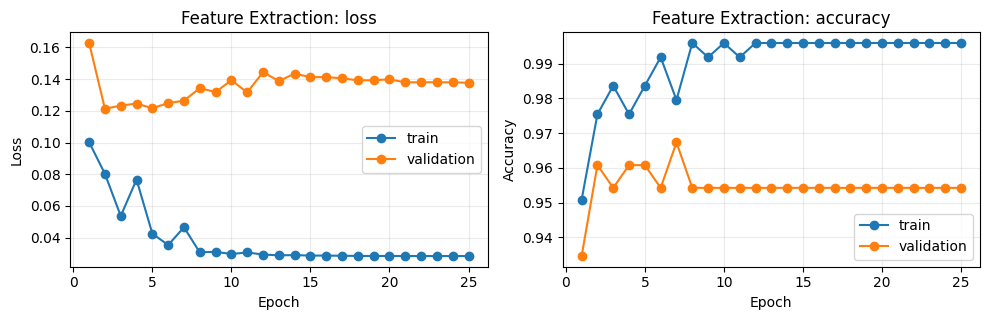

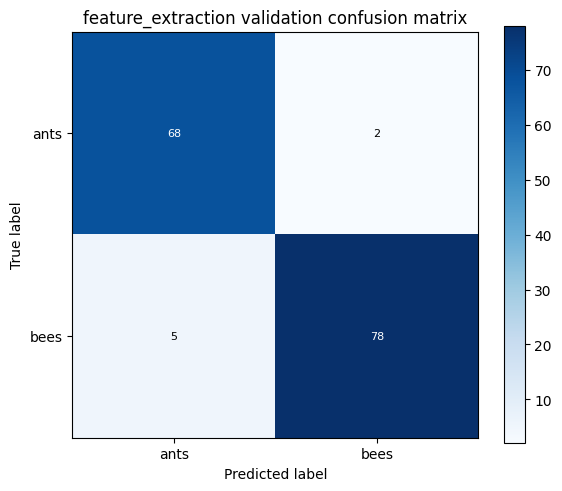

In [4]:
hym_root=DATA/'hymenoptera_data'
if not hym_root.exists():
    download_and_extract_archive('https://download.pytorch.org/tutorial/hymenoptera_data.zip',
                                 str(DATA), filename='hymenoptera_data.zip')
normalization=transforms.Normalize([.485,.456,.406],[.229,.224,.225])
aug=transforms.Compose([transforms.RandomResizedCrop(224),transforms.RandomHorizontalFlip(),
                        transforms.ToTensor(),normalization])
fixed=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(224),transforms.ToTensor(),normalization])
hym_train=datasets.ImageFolder(hym_root/'train',aug)
hym_train_eval=datasets.ImageFolder(hym_root/'train',fixed)
hym_val=datasets.ImageFolder(hym_root/'val',fixed)
assert hym_train.class_to_idx==hym_val.class_to_idx
print('Classes:',hym_train.classes,'train:',len(hym_train),'validation:',len(hym_val))

transfer_results={}
for name,frozen in [('fine_tuning',False),('feature_extraction',True)]:
    seed_all()
    model=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if frozen:
        for p in model.parameters(): p.requires_grad_(False)
    model.fc=nn.Linear(model.fc.in_features,2)
    model=model.to(device)
    optimizer=torch.optim.SGD([p for p in model.parameters() if p.requires_grad],lr=.001,momentum=.9)
    scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=7,gamma=.1)
    print(name,'trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))
    result=train_model(model,loader(hym_train,4,True),loader(hym_train_eval,16),loader(hym_val,16),
                       25,optimizer,2,frozen,scheduler,name)
    transfer_results[name]=result
    curves(result[0],name.replace('_', ' ').title(), eval_label='validation')
    confusion(result[1],hym_train.classes,name+' validation confusion matrix')

## Results and interpretation

In [5]:
rows=[dict(model='Manual dense CIFAR-10',split='test',**manual_history[-1])]
for group,split in [(mnist_results,'test'),(transfer_results,'validation')]:
    for name,(h,cm,seconds) in group.items():
        rows.append(dict(model=name,split=split,seconds=seconds,**h[-1]))
summary=pd.DataFrame(rows)
summary.to_csv(OUT/'summary.csv',index=False)
display(summary[['model','epoch','train_accuracy','test_accuracy','train_loss','test_loss','split']].style.format(
    {'train_accuracy':'{:.2%}','test_accuracy':'{:.2%}','train_loss':'{:.4f}','test_loss':'{:.4f}'}))

for row in rows:
    gap=100*(row['train_accuracy']-row['test_accuracy'])
    display(Markdown(f"**{row['model']}**: training accuracy {row['train_accuracy']:.2%}; "
                     f"{row['split']} accuracy {row['test_accuracy']:.2%}; "
                     f"generalization gap {gap:.2f} percentage points."))
lenet=mnist_results['lenet5'][0][-1]; modern=mnist_results['modern_cnn'][0][-1]
display(Markdown(f"The modern CNN changes MNIST test accuracy by "
                 f"{100*(modern['test_accuracy']-lenet['test_accuracy']):+.2f} percentage points relative to LeNet-5. "
                 "The comparison measures these complete architectures, so any difference cannot be attributed to batch normalization or dropout alone."))
for name,(_,cm,_) in mnist_results.items():
    off=cm.copy(); np.fill_diagonal(off,0)
    i,j=np.unravel_index(off.argmax(),off.shape)
    print(f'{name}: most frequent directed error {i} -> {j}: {off[i,j]} images.')
ft=transfer_results['fine_tuning'][0][-1]; fe=transfer_results['feature_extraction'][0][-1]
display(Markdown(f"Fine tuning changes final validation accuracy by "
                 f"{100*(ft['test_accuracy']-fe['test_accuracy']):+.2f} percentage points relative to feature extraction. "
                 "Fine tuning adapts the representation but estimates many more parameters from a small dataset. "
                 "Feature extraction constrains adaptation and reduces backward computation. "
                 "A single seeded run on this small validation set does not establish statistical superiority."))

,model,epoch,train_accuracy,test_accuracy,train_loss,test_loss,split
0,Manual dense CIFAR-10,10,53.95%,48.03%,1.3567,1.5121,test
1,lenet5,10,99.72%,98.76%,0.0101,0.0406,test
2,modern_cnn,10,98.94%,98.62%,0.0365,0.0443,test
3,fine_tuning,25,99.59%,90.85%,0.0254,0.2044,validation
4,feature_extraction,25,99.59%,95.42%,0.0284,0.1378,validation


**Manual dense CIFAR-10**: training accuracy 53.95%; test accuracy 48.03%; generalization gap 5.92 percentage points.

**lenet5**: training accuracy 99.72%; test accuracy 98.76%; generalization gap 0.95 percentage points.

**modern_cnn**: training accuracy 98.94%; test accuracy 98.62%; generalization gap 0.32 percentage points.

**fine_tuning**: training accuracy 99.59%; validation accuracy 90.85%; generalization gap 8.74 percentage points.

**feature_extraction**: training accuracy 99.59%; validation accuracy 95.42%; generalization gap 4.17 percentage points.

The modern CNN changes MNIST test accuracy by -0.14 percentage points relative to LeNet-5. The comparison measures these complete architectures, so any difference cannot be attributed to batch normalization or dropout alone.

lenet5: most frequent directed error 5 -> 3: 12 images.
modern_cnn: most frequent directed error 9 -> 4: 19 images.


Fine tuning changes final validation accuracy by -4.58 percentage points relative to feature extraction. Fine tuning adapts the representation but estimates many more parameters from a small dataset. Feature extraction constrains adaptation and reduces backward computation. A single seeded run on this small validation set does not establish statistical superiority.

### Discussion of the measured results

**Manual dense network.** CIFAR-10 test accuracy increases from 41.02% after epoch 1 to 48.03% after epoch 10. Test cross-entropy falls from 1.707 to 1.512, so the improvement is visible in both metrics. The final training/test accuracy gap is 5.92 percentage points. The model learns useful class information, but flattening the image removes the spatial inductive bias available to a CNN; this experiment does not isolate the effect of the sigmoid from the other architectural choices.

**MNIST comparison.** LeNet-5 achieves 98.76% test accuracy and the modern CNN achieves 98.62%, a difference of -0.14 percentage points for the modern model. Their training accuracies are 99.72% and 98.94%, respectively. The modern model's smaller training/test gap (0.32 versus 0.95 points) accompanies a lower training fit here; it does not establish that its regularization improves test accuracy. Dropout, global pooling, activation functions and parameter counts all differ, so this is an architecture comparison rather than an ablation study. The confusion matrices and the directed error counts above identify which digits contribute to each model's remaining errors.

**Transfer learning.** Full fine tuning finishes at 99.59% training and 90.85% validation accuracy. Frozen feature extraction finishes at 99.59% training and 95.42% validation accuracy. Frozen feature extraction has the higher final validation accuracy by 4.58 percentage points. With only 153 validation images, one prediction changes accuracy by approximately 0.65 points. These are final-epoch measurements, not the highest points on the validation curves. A larger training/validation gap is consistent with greater overfitting, but differing augmentation and the small split also affect the comparison. Neither validation result should be presented as performance on a separate unseen test set.


### Runtime in this environment

| Model | Training + per-epoch evaluation (s) |
|---|---:|
| lenet5 | 63.4 |
| modern_cnn | 72.1 |
| fine_tuning | 217.9 |
| feature_extraction | 145.1 |

These timings exclude dataset downloads and initial fixed-view caching, and include full training/evaluation passes. GPU utilization, preprocessing and hardware affect the observed difference.

The dense CIFAR-10 network discards spatial structure and uses saturating sigmoid units; its performance should not be compared directly with MNIST accuracy because dataset difficulty differs. A growing training/evaluation accuracy gap is evidence consistent with overfitting; increasing evaluation cross-entropy can also reveal increasingly confident mistakes even when accuracy is stable. The learning curves and confusion matrices above provide the evidence for this run.

Limitations: one seed per model, no independent hymenoptera test set, and no hyperparameter search. Per-epoch evaluation is required by the brief but repeated test inspection should not guide tuning. Runtime includes training and full per-epoch evaluation. Reproducibility can vary across GPU and library versions.